# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Sherlock Chen, Henry Fong, Edward Christopher

**Date:** 11/16/2026

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB

Seed: 65
Tree Model Performa

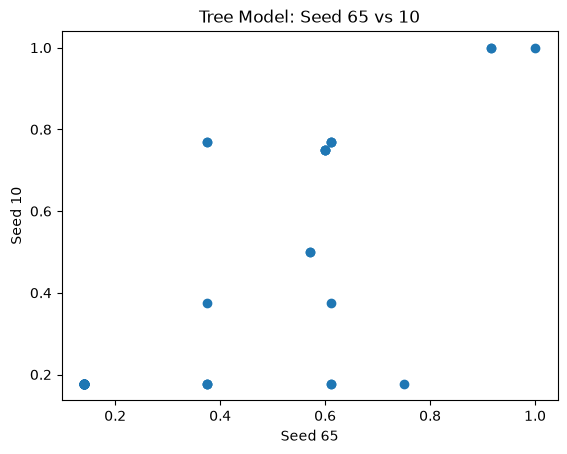

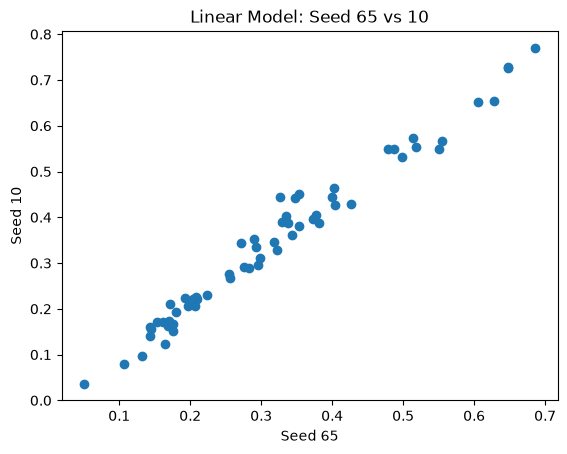

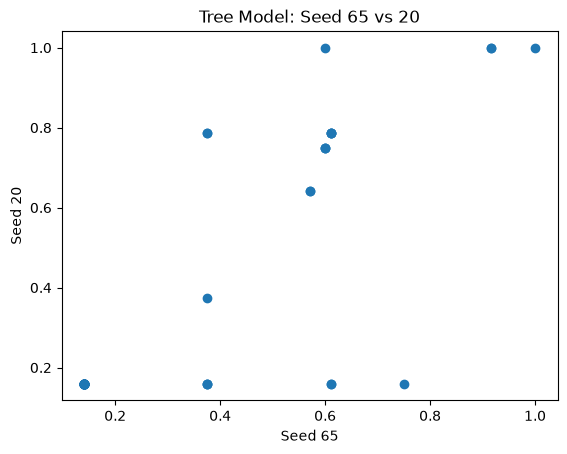

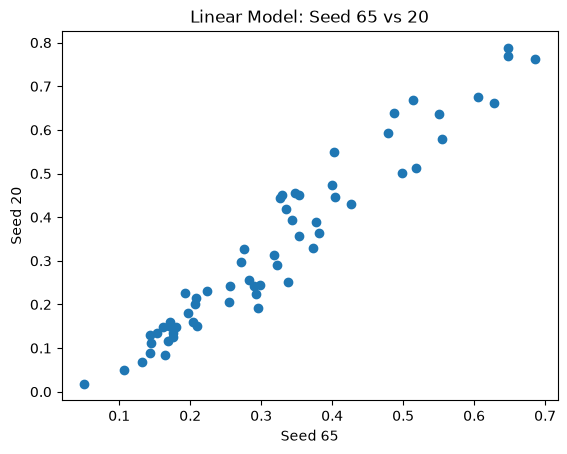

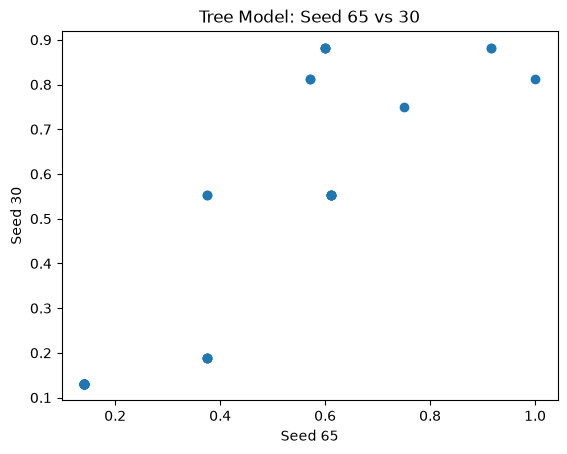

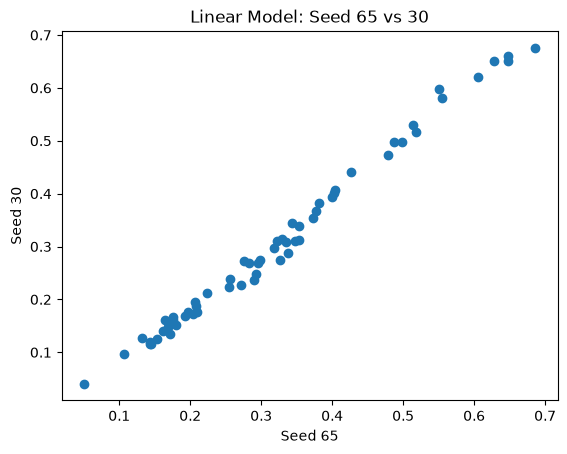

Tree Correlation for Seed 65 vs 10: 0.8174786550095476
Linear Correlation for Seed 65 vs 10: 0.9874091061813592

Tree Correlation for Seed 65 vs 20: 0.8272070410890748
Linear Correlation for Seed 65 vs 20: 0.966890504641773

Tree Correlation for Seed 65 vs 30: 0.9234868886826785
Linear Correlation for Seed 65 vs 30: 0.9951541629984919

Tree Model Seed 65 vs 10:
Intercept: 0.053553342519965075
Slope: 0.8803278473379089
R2: 0.6682713513962191

Linear Model Seed 65 vs 10:
Intercept: -0.011203891720173775
Slope: 1.1206286194793034
R2: 0.9749767429698699

Tree Model Seed 65 vs 20:
Intercept: 0.024648145825362677
Slope: 0.9880797428983428
R2: 0.6842714888273428

Linear Model Seed 65 vs 20:
Intercept: -0.07657250587821401
Slope: 1.2764764953144894
R2: 0.9348772479664221

Tree Model Seed 65 vs 30:
Intercept: -0.014708109370373978
Slope: 1.060858885760349
R2: 0.8528280335688145

Linear Model Seed 65 vs 30:
Intercept: -0.03772110937239498
Slope: 1.0735362450171122
R2: 0.9903318081332293



In [ ]:
# Your Phase 1 solution to the problem goes here.
import pandas as pd

# Question 1
path = "data/heart_failure/heart_failure_clinical_records_dataset.csv"
df = pd.read_csv(path)

# Check out dataset
df.info()
df.describe()

# No null values in dataset
df.isnull().sum()

# Question 2
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

X = df[["age", "ejection_fraction", "serum_sodium"]]
y = df["DEATH_EVENT"]
random_state_seed = 65

# Split train and test data
X_train_base, X_test_base, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=random_state_seed)

# Tree model
tree_model = DecisionTreeClassifier(max_depth=3, random_state=random_state_seed)
tree_model.fit(X_train_base, y_train)
tree_predict = tree_model.predict_proba(X_test_base)[:, 1]
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_predict))
tree_r2 = r2_score(y_test, tree_predict)

# Linear model
linear_model = LogisticRegression(random_state=random_state_seed)
linear_model.fit(X_train_base, y_train)
linear_predict = linear_model.predict_proba(X_test_base)[:, 1]
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predict))
linear_r2 = r2_score(y_test, linear_predict)

# Evaluation of models
print(f"\nSeed: {random_state_seed}")
print("Tree Model Performance: ")
print(f"RMSE: {tree_rmse}, R2: {tree_r2}")
print("Linear Model Performance: ")
print(f"RMSE: {linear_rmse}, R2: {linear_r2}")

# Question 3
additional_random_state_seeds = [10, 20, 30]
tree_predictions_dict = {}
linear_predictions_dict = {}

# Save predictions from question 2 first
tree_predictions_dict[random_state_seed] = tree_predict
linear_predictions_dict[random_state_seed] = linear_predict

# Loop for each seed
for seed in additional_random_state_seeds:
    # Split train and test data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=seed)

    # Tree model
    tree_model = DecisionTreeClassifier(max_depth=3, random_state=seed)
    tree_model.fit(X_train, y_train)
    tree_predict = tree_model.predict_proba(X_test)[:, 1]
    tree_rmse = np.sqrt(mean_squared_error(y_test, tree_predict))
    tree_r2 = r2_score(y_test, tree_predict)

    # Linear model
    linear_model = LogisticRegression(random_state=seed)
    linear_model.fit(X_train, y_train)
    linear_predict = linear_model.predict_proba(X_test)[:, 1]
    linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predict))
    linear_r2 = r2_score(y_test, linear_predict)

    # Save predictions
    tree_predictions_dict[seed] = tree_model.predict_proba(X_test_base)[:, 1]
    linear_predictions_dict[seed] = linear_model.predict_proba(X_test_base)[:, 1]

    # Evaluation of models
    print(f"\nSeed: {seed}")
    print("Tree Model Performance: ")
    print(f"RMSE: {tree_rmse}, R2: {tree_r2}")
    print("Linear Model Performance: ")
    print(f"RMSE: {linear_rmse}, R2: {linear_r2}")
    print("Linear Model Coefficients:", linear_model.coef_)

# It looks like for tree models, the results are very varied (for example R2 values ranging from -0.19 to 0.24)
# The linear model coefficients are all around the same values regardless of seeds.

# Question 4a
import matplotlib.pyplot as plt

for seed in additional_random_state_seeds:
    # Tree model scatter plots
    plt.scatter(tree_predictions_dict[random_state_seed], tree_predictions_dict[seed])
    plt.title(f"Tree Model: Seed {random_state_seed} vs {seed}")
    plt.xlabel(f"Seed {random_state_seed}")
    plt.ylabel(f"Seed {seed}")
    plt.show()

    # Linear model scatter plots
    plt.scatter(linear_predictions_dict[random_state_seed], linear_predictions_dict[seed])
    plt.title(f"Linear Model: Seed {random_state_seed} vs {seed}")
    plt.xlabel(f"Seed {random_state_seed}")
    plt.ylabel(f"Seed {seed}")
    plt.show()

# The plots for linear all look reasonably similar for linear models because they all cluster together to create an upwards trend, showing that they are relatively stable over different seeds.
# The plots for trees are not similar as they are just scattered with less alignment than linear across the different seeds

# Question 4b
for seed in additional_random_state_seeds:
    tree_correlation = pd.Series(tree_predictions_dict[random_state_seed]).corr(pd.Series(tree_predictions_dict[seed]))
    linear_correlation = pd.Series(linear_predictions_dict[random_state_seed]).corr(pd.Series(linear_predictions_dict[seed]))

    print(f"Tree Correlation for Seed {random_state_seed} vs {seed}: {tree_correlation}")
    print(f"Linear Correlation for Seed {random_state_seed} vs {seed}: {linear_correlation}\n")

# Both the correlations are very high, with the linear models being higher (around 0.9) than the tree models (around 0.8), showing that linear models are still more stable than tree models

# Question 4c
from sklearn.linear_model import LinearRegression

for seed in additional_random_state_seeds:
    regression_tree = LinearRegression().fit(tree_predictions_dict[random_state_seed].reshape(-1,1), tree_predictions_dict[seed])
    print(f"Tree Model Seed {random_state_seed} vs {seed}:")
    print(f"Intercept: {regression_tree.intercept_}")
    print(f"Slope: {regression_tree.coef_[0]}")
    print(f"R2: {regression_tree.score(tree_predictions_dict[random_state_seed].reshape(-1, 1), tree_predictions_dict[seed])}\n")
    
    regression_linear = LinearRegression().fit(linear_predictions_dict[random_state_seed].reshape(-1, 1), linear_predictions_dict[seed])
    print(f"Linear Model Seed {random_state_seed} vs {seed}:")
    print(f"Intercept: {regression_linear.intercept_}")
    print(f"Slope: {regression_linear.coef_[0]}")
    print(f"R2: {regression_linear.score(linear_predictions_dict[random_state_seed].reshape(-1,1), linear_predictions_dict[seed])}\n")

# The intercepts are close to zero, meaning the predictions start at similar levels
# The slops are close to 1, meaning there is one to one alignment
# The R2 values are close to 1 meaning the predictions are good indicators for explanations

# Question 5
# Linear models seem to have similar coefficents across different train/test splits and their predictions are also very similar.
# The tree models also have similar predictions but their split structures are very different across different seeds.

# Question 6
# True, because even thought he decision trees looked different across different seeds, the predictions they generated were still pretty similar.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]